# Casco de ciclista con direccionales por inclinación de la cabeza
**Práctica: clasificador de gestos con IMU (1D-CNN) · exportación a TFLite, C++ y TensorFlow.js**

Es la versión para sensores de la práctica *FrutaLens*. Cambia la entrada (ya no son imágenes sino una **ventana de 1,5 s de un IMU de 6 canales**) y, con ella, el modelo: no existe un MobileNetV2 preentrenado para esta señal, así que se entrena una **1D-CNN pequeña desde cero** (≈ 6 mil parámetros) con datos propios.

| Aspecto | FrutaLens | Casco |
|---|---|---|
| Entrada | imagen 160×160×3 | ventana 75×6 (ax, ay, az, gx, gy, gz) a 50 Hz |
| Modelo | MobileNetV2 congelado + Dense | 1D-CNN de 3 capas convolucionales + Dense |
| Clases | manzana, banana, naranja | **neutro**, **izquierda**, **derecha** |
| División | Training/Test del dataset | **por persona** (nunca por ventana al azar) |
| Salida web | TF.js GraphModel | TF.js GraphModel + **TFLite int8** + pesos para C++ |

> **Aviso honesto sobre los datos.** Este cuaderno trae un *generador sintético* para que todo el flujo se pueda ejecutar sin hardware. Las métricas obtenidas con datos sintéticos **solo validan el flujo**, no el comportamiento con una persona real sobre una bicicleta. Para un resultado con valor real hay que grabar sesiones con el casco (sección 17) y reentrenar.

> **Seguridad.** Prototipo educativo, no certificado. Una luz que falla o se enciende por error es un riesgo. El casco debe tener siempre una luz de posición fija independiente del modelo.

## 1. Alcance y criterios de aceptación
**Clases:** `neutro`, `izquierda`, `derecha`. **Gesto:** inclinación lateral sostenida de la cabeza (oreja hacia el hombro): inclinar a la derecha enciende la luz derecha y a la izquierda, la izquierda. Mirar sobre el hombro, baches, frenadas y asentir **no** deben encender nada.

- **F1 – Validar una ventana de entrada:** 75 muestras × 6 canales, valores finitos, |aceleración| ≤ 16 g, |giro| ≤ 2000 °/s y señal no constante. Si falla, se rechaza con un mensaje y **no se invoca el modelo**.
- **F2 – Clasificar y señalizar:** devuelve clase y puntaje por clase; por debajo de 0,70 se trata como `neutro`; la luz se enciende tras 2 predicciones consecutivas iguales y se apaga tras 3 sin gesto; límite de 10 s continuos.

| Criterio | Valor |
|---|---|
| Frecuencia de muestreo | 50 Hz |
| Ventana | 75 muestras (1,5 s); inferencia cada 10 muestras (200 ms) |
| Exactitud en personas no vistas | informar, sin umbral fijo (referencia de práctica ≥ 0,90) |
| Falsas activaciones en conducción normal | informar por hora (referencia de práctica: < 6 por hora) |
| Determinismo | misma ventana → misma clase y diferencia de puntaje ≤ 0,000001 |
| Latencia de inferencia | < 300 ms (en PC y, medida aparte, en el microcontrolador) |

**Límites:** la exactitud no demuestra calidad integral; el puntaje no es una probabilidad calibrada; no se reconocen gestos fuera de las tres clases ni se garantiza generalización a otras personas, cascos o terrenos.

## 2. Entorno
Python 3.10–3.12. La primera celda instala versiones compatibles con la exportación web; si pide reiniciar, reinicie el kernel y ejecute de nuevo. Para el convertidor se recomienda Linux o Colab.

In [1]:
import os, sys, subprocess
if os.environ.get("CASCO_SKIP_INSTALL") != "1":
    # Versiones probadas en conjunto para exportar a TF.js (ver README, "Problemas conocidos").
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "tensorflow==2.18.*", "tensorflowjs==4.22.0", "numpy<2",
                    "pandas", "scikit-learn", "matplotlib"], check=False)

import json, hashlib, time, shutil, zipfile, platform, warnings
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
warnings.filterwarnings("ignore")
try:
    import tensorflowjs as tfjs
    TFJS_VERSION = tfjs.__version__
except Exception as e:                       # la exportación web se omite si falla; el resto funciona
    tfjs, TFJS_VERSION = None, f"no disponible ({type(e).__name__})"

SEED = 42
tf.keras.utils.set_random_seed(SEED)
VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "tensorflow": tf.__version__, "keras": tf.keras.__version__, "tensorflowjs": TFJS_VERSION}
print(json.dumps(VERSIONES, indent=2))
OUT = "salida"
for d in ("datos/sesiones", "modelo", "evidencias"):
    os.makedirs(os.path.join(OUT, d), exist_ok=True)

{
  "python": "3.12.3",
  "numpy": "1.26.4",
  "pandas": "2.2.3",
  "tensorflow": "2.18.1",
  "keras": "3.8.0",
  "tensorflowjs": "4.22.0"
}


## 3. Convenciones (iguales en el cuaderno, el simulador web y el firmware)
Sistema de ejes del casco, con el sensor detrás de la cabeza y la persona mirando al frente:
- **x** hacia adelante, **y** hacia la **izquierda** de la persona, **z** hacia arriba.
- **Roll (φ)** positivo = inclinar la cabeza hacia la **derecha**. En reposo y erguido el acelerómetro mide `(0, 0, +1 g)`.
- Inclinar a la derecha → `ay > 0`; inclinar a la izquierda → `ay < 0`.
- **Pitch (θ)** positivo = mirar hacia abajo. **Yaw (ψ)** positivo = girar hacia la izquierda.
- Aceleración en **g**, giroscopio en **°/s**. Orden de canales: `ax, ay, az, gx, gy, gz`.

In [2]:
FS = 50; WIN = 75; HOP = 10; N_CH = 6
CLASES = ["neutro", "izquierda", "derecha"]          # el orden define las salidas del modelo
CANALES = ["ax", "ay", "az", "gx", "gy", "gz"]
UMBRAL_CONF = 0.70; ON_N = 2; OFF_N = 3; MAX_SENAL_S = 10.0
ACC_MAX_G, GYR_MAX_DPS = 16.0, 2000.0                # límites de validación F1
CLIP_ACC, CLIP_GYR = 4.0, 500.0                      # rango físico del sensor (±4 g, ±500 °/s)

## 4. Datos: generador sintético y carga de sesiones reales
Cada **sesión** es una grabación continua (CSV con `t_ms, ax, ay, az, gx, gy, gz, label`). El generador sintético simula una persona con una bicicleta: vibración del camino, balanceo al pedalear, baches, frenadas, asentir, **mirar sobre el hombro** (giro de cabeza), sacudidas rápidas, inclinaciones leves y de espejo (negativos difíciles) y las señales deliberadas (inclinación lateral sostenida).

La física es consistente: a partir de los ángulos (roll, pitch, yaw) se calcula lo que mediría un IMU real (gravedad proyectada + velocidades angulares del cuerpo), se añade desalineación de montaje, sesgo, ruido y saturación.

**Honestidad:** esto es una simulación hecha por quien escribe el código; los baches, las personas y los gestos reales serán distintos. Úsela para validar el flujo y para comparar modelos, y luego reentrene con datos propios.

In [3]:
def _ss(x):
    x = np.clip(x, 0.0, 1.0); return x * x * (3 - 2 * x)

def _forma(n, i0, subida, meseta, bajada):
    """Pulso suave 0→1→0: sube en `subida` muestras, se mantiene `meseta` y baja en `bajada`."""
    t = np.arange(n)
    up = _ss((t - i0) / max(subida, 1))
    down = 1.0 - _ss((t - (i0 + subida + meseta)) / max(bajada, 1))
    return np.minimum(up, down)

def _rot(ax_deg, ay_deg, az_deg):
    a, b, c = np.deg2rad([ax_deg, ay_deg, az_deg])
    Rx = np.array([[1, 0, 0], [0, np.cos(a), -np.sin(a)], [0, np.sin(a), np.cos(a)]])
    Ry = np.array([[np.cos(b), 0, np.sin(b)], [0, 1, 0], [-np.sin(b), 0, np.cos(b)]])
    Rz = np.array([[np.cos(c), -np.sin(c), 0], [np.sin(c), np.cos(c), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx

def crear_persona(rng, pid):
    return dict(id=pid,
        tilt_amp=rng.uniform(18, 34),            # inclinación deliberada (°)
        subida=rng.uniform(0.25, 0.6),           # s
        meseta=(rng.uniform(0.9, 1.5), rng.uniform(1.6, 2.8)),   # s sostenida
        postura_pitch=float(np.clip(rng.normal(12, 6), 0, 25)),  # cabeza algo agachada en la bici
        balanceo=rng.uniform(1.0, 3.5), pedal_hz=rng.uniform(0.7, 1.3),
        ruido_a=rng.uniform(0.008, 0.025), ruido_g=rng.uniform(0.5, 1.5),
        sesgo_a=rng.normal(0, 0.02, 3), sesgo_g=rng.normal(0, 1.0, 3),
        vib=rng.uniform(0.03, 0.11),             # vibración del camino (g)
        montaje=rng.normal(0, 3.0, 3),           # desalineación del sensor en el casco (°)
        giro_hombro=rng.uniform(50, 90))

EVENTOS = ["izq", "der", "mirar", "asentir", "frenada", "leve", "sacudida", "espejo"]
PESOS   = [0.18, 0.18, 0.15, 0.07, 0.06, 0.12, 0.07, 0.17]

def simular_sesion(rng, p, dur_s=90.0, tasa_baches=None, guion=None, baches_en=None):
    """Devuelve X (n,6), y (n,) con 0/1/2 y la lista de señales deliberadas [(clase, inicio, fin)] en muestras.
    guion=[(segundo, evento, lado)] fija los eventos (pruebas); baches_en=[segundos] fija los baches."""
    n = int(dur_s * FS); t = np.arange(n) / FS
    roll = np.zeros(n); pitch = np.zeros(n); yaw = np.zeros(n)
    a_lin = np.zeros((n, 3)); y = np.zeros(n, dtype=np.int8); senales = []
    if tasa_baches is None: tasa_baches = rng.uniform(0.01, 0.12)

    # postura base y balanceo de pedaleo
    walk = np.cumsum(rng.normal(0, 0.05, n)); walk -= np.convolve(walk, np.ones(100) / 100, "same")
    roll += p["balanceo"] * np.sin(2 * np.pi * p["pedal_hz"] * t + rng.uniform(0, 6.28)) + 1.5 * walk
    pitch += p["postura_pitch"] + 1.0 * np.sin(2 * np.pi * 2 * p["pedal_hz"] * t) + 1.5 * np.roll(walk, 77)
    yaw += 1.0 * np.roll(walk, 150)

    def aplicar(ev, i, lado):
        """Suma el evento a los ángulos/aceleraciones y devuelve su duración en muestras."""
        if ev in ("izq", "der"):
            sub = int(p["subida"] * rng.uniform(0.9, 1.2) * FS)
            mes = int(rng.uniform(*p["meseta"]) * FS); baj = int(rng.uniform(0.3, 0.6) * FS)
            A = p["tilt_amp"] * rng.uniform(0.85, 1.15); sg = -1 if ev == "izq" else 1
            f = _forma(n, i, sub, mes, baj)
            roll[:] += sg * A * f; pitch[:] += rng.uniform(-3, 5) * f; yaw[:] += rng.uniform(-5, 5) * f
            cls = 1 if ev == "izq" else 2
            mask = (f >= 0.6) & (np.arange(n) <= i + sub + mes)
            y[mask] = cls
            idx = np.where(mask)[0]
            if len(idx): senales.append((cls, int(idx[0]), int(idx[-1])))
            return sub + mes + baj
        if ev == "mirar":        # mirar sobre el hombro: giro de cabeza (yaw) con algo de roll/pitch
            sub = int(rng.uniform(0.25, 0.5) * FS); mes = int(rng.uniform(0.4, 1.2) * FS); baj = int(rng.uniform(0.3, 0.6) * FS)
            f = _forma(n, i, sub, mes, baj)
            yaw[:] += lado * p["giro_hombro"] * rng.uniform(0.8, 1.1) * f
            roll[:] += rng.uniform(-9, 9) * f; pitch[:] += rng.uniform(-5, 10) * f
            return sub + mes + baj
        if ev == "asentir":      # mirar al suelo / ajustar la vista
            sub = int(rng.uniform(0.2, 0.4) * FS); mes = int(rng.uniform(0.1, 0.5) * FS); baj = int(rng.uniform(0.3, 0.5) * FS)
            pitch[:] += rng.uniform(15, 30) * _forma(n, i, sub, mes, baj)
            return sub + mes + baj
        if ev == "frenada":
            sub = int(0.3 * FS); mes = int(rng.uniform(0.6, 2.0) * FS); baj = int(0.5 * FS)
            f = _forma(n, i, sub, mes, baj)
            a_lin[:, 0] -= rng.uniform(0.15, 0.45) * f; pitch[:] += rng.uniform(2, 8) * f
            return sub + mes + baj
        if ev == "leve":         # inclinación pequeña: no es una señal
            sub = int(0.4 * FS); mes = int(rng.uniform(0.5, 1.5) * FS); baj = int(0.4 * FS)
            roll[:] += lado * rng.uniform(4, 11) * _forma(n, i, sub, mes, baj)
            return sub + mes + baj
        if ev == "sacudida":     # tirón rápido, sin sostener
            sub = int(0.1 * FS); mes = int(rng.uniform(0.0, 0.2) * FS); baj = int(0.15 * FS)
            roll[:] += lado * rng.uniform(15, 28) * _forma(n, i, sub, mes, baj)
            return sub + mes + baj
        if ev == "espejo":       # inclinar para mirar el tráfico: breve y de amplitud cercana a la señal
            sub = int(rng.uniform(0.25, 0.4) * FS); mes = int(rng.uniform(0.2, 0.6) * FS); baj = int(rng.uniform(0.3, 0.5) * FS)
            roll[:] += lado * rng.uniform(12, 17) * _forma(n, i, sub, mes, baj)
            return sub + mes + baj
        raise ValueError(ev)

    if guion is None:
        i = int(rng.uniform(2, 5) * FS)
        while i < n - 4 * FS:
            ev = rng.choice(EVENTOS, p=np.array(PESOS) / sum(PESOS)); lado = int(rng.choice([-1, 1]))
            i += aplicar(ev, i, lado) + int(rng.uniform(1.5, 5.0) * FS)
    else:
        for seg, ev, lado in guion: aplicar(ev, int(seg * FS), lado)

    # baches (en cualquier momento, también durante una señal)
    if baches_en is None:
        pos = rng.choice(n, size=rng.poisson(tasa_baches * dur_s)) if tasa_baches > 0 else []
        amps = [rng.uniform(0.4, 2.0) for _ in pos]
    else:
        pos = [int(s * FS) for s in baches_en]; amps = [2.0] * len(pos)
    for ib, amp in zip(pos, amps):
        f0 = rng.uniform(8, 14); tau = rng.uniform(0.08, 0.2)
        k = np.arange(0, min(int(0.8 * FS), n - ib)); osc = np.exp(-k / FS / tau) * np.sin(2 * np.pi * f0 * k / FS)
        a_lin[ib:ib + len(k), 2] += amp * osc * rng.choice([-1, 1])
        a_lin[ib:ib + len(k), 0] += 0.3 * amp * osc * rng.uniform(-1, 1)
        a_lin[ib:ib + len(k), 1] += 0.3 * amp * osc * rng.uniform(-1, 1)
        roll[ib:ib + len(k)] += rng.uniform(1, 4) * osc * rng.choice([-1, 1])
        pitch[ib:ib + len(k)] += rng.uniform(1, 4) * osc * rng.choice([-1, 1])

    # vibración continua del camino
    mod = 0.7 + 0.3 * np.sin(2 * np.pi * rng.uniform(0.02, 0.08) * t + rng.uniform(0, 6.28))
    gv = np.zeros((n, 3))
    for amp_rel in (1.0, 0.6, 0.4):
        f = rng.uniform(6, 22)
        for c in range(3):
            s = np.sin(2 * np.pi * f * t + rng.uniform(0, 6.28)) * mod * p["vib"] * amp_rel
            a_lin[:, c] += s * (1.0 if c == 2 else 0.6); gv[:, c] += s * 40.0

    # de ángulos a lo que mide un IMU: gravedad proyectada + velocidades angulares del cuerpo
    phi, th, psi = np.deg2rad(roll), np.deg2rad(pitch), np.deg2rad(yaw)
    dphi, dth, dpsi = (np.gradient(a, 1 / FS) for a in (phi, th, psi))
    acc = np.stack([-np.sin(th), np.sin(phi) * np.cos(th), np.cos(phi) * np.cos(th)], 1) + a_lin
    gyr = np.rad2deg(np.stack([dphi - dpsi * np.sin(th),
                               dth * np.cos(phi) + dpsi * np.sin(phi) * np.cos(th),
                               -dth * np.sin(phi) + dpsi * np.cos(phi) * np.cos(th)], 1)) + gv
    Rm = _rot(*p["montaje"])
    acc = acc @ Rm.T + p["sesgo_a"] + rng.normal(0, p["ruido_a"], (n, 3))
    gyr = gyr @ Rm.T + p["sesgo_g"] + rng.normal(0, p["ruido_g"], (n, 3))
    X = np.clip(np.hstack([acc, gyr]), [-CLIP_ACC] * 3 + [-CLIP_GYR] * 3, [CLIP_ACC] * 3 + [CLIP_GYR] * 3)
    return X.astype(np.float32), y, senales

def cargar_sesion_csv(ruta):
    """Carga una sesión REAL grabada con herramientas/captura_serial.py (o equivalente).
    Columnas: t_ms, ax, ay, az, gx, gy, gz, label (neutro|izquierda|derecha). Remuestrea a 50 Hz."""
    df = pd.read_csv(ruta)
    faltan = [c for c in ["ax", "ay", "az", "gx", "gy", "gz", "label"] if c not in df.columns]
    if faltan: raise ValueError(f"{ruta}: faltan columnas {faltan}")
    if df[CANALES].isna().any().any(): raise ValueError(f"{ruta}: contiene NaN")
    if "t_ms" in df.columns:
        t = df["t_ms"].to_numpy(float) / 1000.0
        tn = np.arange(t[0], t[-1], 1 / FS)
        X = np.stack([np.interp(tn, t, df[c].to_numpy(float)) for c in CANALES], 1)
        idx = np.clip(np.searchsorted(t, tn), 0, len(df) - 1)
        lab = df["label"].to_numpy()[idx]
    else:
        X = df[CANALES].to_numpy(float); lab = df["label"].to_numpy()
    y = np.array([CLASES.index(l) for l in lab], dtype=np.int8)
    return X.astype(np.float32), y

## 5. Generar (o cargar) el dataset y registrar el manifiesto
`USAR_DATOS_REALES = True` lee `datos_reales/*.csv` con nombre `pXX_sY.csv` (persona XX, sesión Y) en lugar del generador. El manifiesto guarda persona, sesión, rol (train/val/test), semilla, duración y huella SHA-256 de cada archivo.

**División por persona:** 16 personas simuladas → 10 entrenamiento, 3 validación, 3 prueba. Las personas de prueba **no se usan para ajustar nada**.

In [4]:
USAR_DATOS_REALES = False
N_PERSONAS, SESIONES_POR_PERSONA, DUR_SESION_S = 16, 3, 90
ROL = {p: ("train" if p < 10 else "val" if p < 13 else "test") for p in range(N_PERSONAS)}

sesiones = []   # cada una: dict(persona, sesion, rol, X, y, senales)
ruta_ses = os.path.join(OUT, "datos", "sesiones")
if USAR_DATOS_REALES:
    import glob, re
    for f in sorted(glob.glob("datos_reales/p*_s*.csv")):
        m = re.match(r"p(\d+)_s(\d+)\.csv", os.path.basename(f)); pid, sid = int(m[1]), int(m[2])
        X, y = cargar_sesion_csv(f)
        sesiones.append(dict(persona=pid, sesion=sid, X=X, y=y, senales=[], semilla=None, archivo=f))
    pids = sorted({s["persona"] for s in sesiones}); n = len(pids)
    ROL = {p: ("train" if k < n * 0.65 else "val" if k < n * 0.82 else "test") for k, p in enumerate(pids)}
    for s in sesiones: s["rol"] = ROL[s["persona"]]
else:
    for pid in range(N_PERSONAS):
        persona = crear_persona(np.random.default_rng(1000 + pid), pid)
        for sid in range(SESIONES_POR_PERSONA):
            semilla = 100000 + pid * 100 + sid
            X, y, sen = simular_sesion(np.random.default_rng(semilla), persona, DUR_SESION_S)
            archivo = os.path.join(ruta_ses, f"p{pid:02d}_s{sid}.csv")
            df = pd.DataFrame(X, columns=CANALES); df.insert(0, "t_ms", (np.arange(len(X)) * 1000 // FS).astype(int))
            df["label"] = [CLASES[k] for k in y]; df.to_csv(archivo, index=False, float_format="%.5f")
            sesiones.append(dict(persona=pid, sesion=sid, rol=ROL[pid], X=X, y=y, senales=sen, semilla=semilla, archivo=archivo))

manifiesto = pd.DataFrame([dict(persona=s["persona"], sesion=s["sesion"], rol=s["rol"], semilla=s["semilla"],
                                muestras=len(s["X"]), segundos=round(len(s["X"]) / FS, 1),
                                senales=len(s["senales"]), sha256=hashlib.sha256(open(s["archivo"], "rb").read()).hexdigest()[:16])
                           for s in sesiones])
manifiesto.to_csv(os.path.join(OUT, "evidencias", "manifiesto_datos.csv"), index=False)
print(f"{len(sesiones)} sesiones · {manifiesto.segundos.sum() / 60:.0f} min en total")
display(manifiesto.groupby("rol").agg(sesiones=("sesion", "count"), minutos=("segundos", lambda s: round(s.sum() / 60, 1)), senales=("senales", "sum")))

48 sesiones · 72 min en total


,sesiones,minutos,senales
rol,,,
test,9,13.5,61
train,30,45.0,182
val,9,13.5,45


## 6. Inspección de las muestras
Una ventana típica de cada comportamiento. Observe que **mirar sobre el hombro** se ve sobre todo en el giroscopio (`gz`, `gx`), mientras que la **inclinación deliberada** cambia `ay` (gravedad) de forma sostenida; un **bache** es un pico corto en `az`.

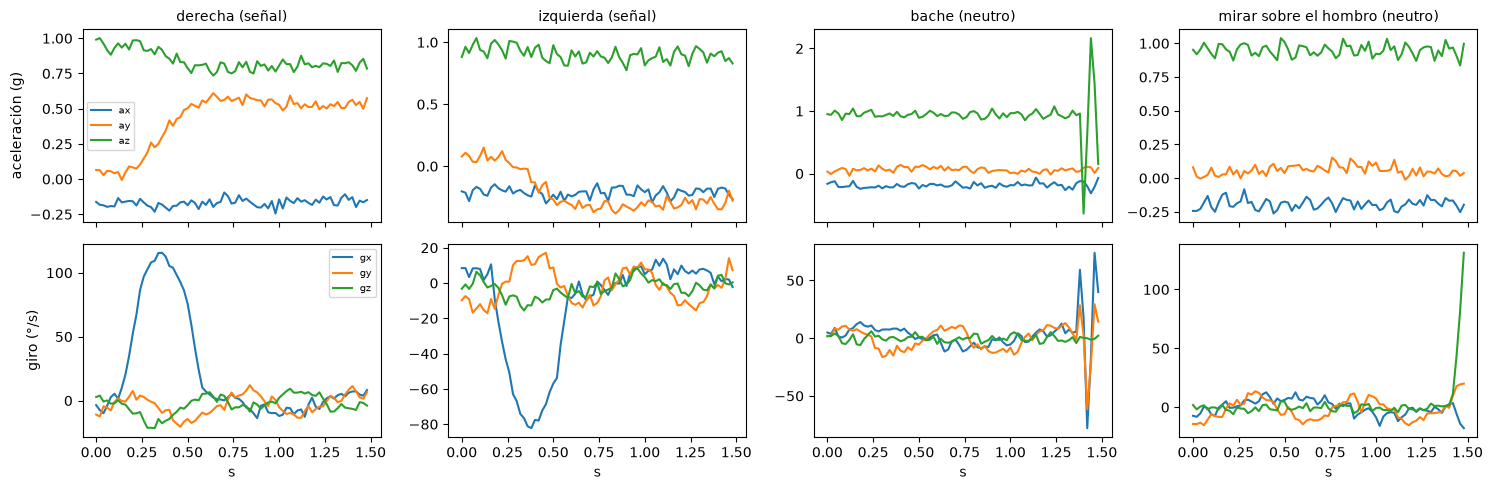

In [5]:
def extraer(X, i0, n=WIN): return X[i0:i0 + n]
s0 = next(s for s in sesiones if s["rol"] == "train" and len(s["senales"]) >= 2)
cls_i = [x for x in s0["senales"] if x[0] == 1][0]; cls_d = [x for x in s0["senales"] if x[0] == 2][0]
ejemplos = {"derecha (señal)": extraer(s0["X"], max(cls_d[1] - 20, 0)),
            "izquierda (señal)": extraer(s0["X"], max(cls_i[1] - 20, 0))}
# un bache y un mirar-sobre-el-hombro cualquiera (en sesiones de entrenamiento, ventana sin etiqueta de señal)
def buscar_neutro(cond):
    for s in sesiones:
        if s["rol"] != "train": continue
        for i0 in range(0, len(s["X"]) - WIN, 5):
            w = s["X"][i0:i0 + WIN]
            if (s["y"][i0:i0 + WIN] == 0).all() and cond(w): return w
bache = buscar_neutro(lambda w: np.abs(w[:, 2] - np.median(w[:, 2])).max() > 1.0)
mirar = buscar_neutro(lambda w: np.abs(w[:, 5]).max() > 60 and np.abs(w[:, 1]).max() < 0.2)
ejemplos["bache (neutro)"] = bache; ejemplos["mirar sobre el hombro (neutro)"] = mirar
fig, axs = plt.subplots(2, 4, figsize=(15, 5), sharex=True)
for k, (nombre, w) in enumerate(ejemplos.items()):
    t = np.arange(WIN) / FS
    for c in range(3): axs[0, k].plot(t, w[:, c], label=CANALES[c])
    for c in range(3, 6): axs[1, k].plot(t, w[:, c], label=CANALES[c])
    axs[0, k].set_title(nombre, fontsize=10); axs[1, k].set_xlabel("s")
axs[0, 0].set_ylabel("aceleración (g)"); axs[1, 0].set_ylabel("giro (°/s)")
axs[0, 0].legend(fontsize=7); axs[1, 0].legend(fontsize=7); plt.tight_layout()
plt.savefig(os.path.join(OUT, "evidencias", "ejemplos_ventanas.png"), dpi=110); plt.show()

## 7. F1 · Validación de una ventana y preparación de ventanas
`validar_ventana` es la función de **F1**: rechaza antes de invocar el modelo. El etiquetado de ventanas usa el **estado al final de la ventana** (últimas 25 muestras = 0,5 s): es lo que el casco necesita saber *ahora*, y se descartan las ventanas de transición donde esa porción no está en un único estado (pureza < 0,8). Se eliminan ventanas duplicadas exactas.

In [6]:
def validar_ventana(x):
    """F1. Devuelve (ok, mensaje). No toca el modelo."""
    try: x = np.asarray(x, dtype=np.float64)
    except Exception: return False, "La ventana no es numérica."
    if x.ndim != 2 or x.shape != (WIN, N_CH): return False, f"Forma incorrecta {x.shape}; se esperaba ({WIN}, {N_CH})."
    if not np.isfinite(x).all(): return False, "La ventana contiene valores NaN o infinitos."
    if np.abs(x[:, :3]).max() > ACC_MAX_G: return False, f"Aceleración fuera de rango (> {ACC_MAX_G} g)."
    if np.abs(x[:, 3:]).max() > GYR_MAX_DPS: return False, f"Giro fuera de rango (> {GYR_MAX_DPS} °/s)."
    if np.all(x.std(axis=0) < 1e-6): return False, "Señal constante: el sensor parece desconectado."
    return True, "OK"

def ventanear(sesiones_rol, hop=HOP):
    Xs, ys, meta, vistos = [], [], [], set(); dup = 0; trans = 0
    for s in sesiones_rol:
        X, y = s["X"], s["y"]
        for i0 in range(0, len(X) - WIN + 1, hop):
            fin = y[i0 + WIN - 25:i0 + WIN]; cls = np.bincount(fin, minlength=3).argmax()
            if (fin == cls).mean() < 0.8: trans += 1; continue
            w = X[i0:i0 + WIN]; h = hashlib.md5(w.tobytes()).hexdigest()
            if h in vistos: dup += 1; continue
            vistos.add(h); Xs.append(w); ys.append(cls); meta.append((s["persona"], s["sesion"], i0))
    return np.stack(Xs).astype(np.float32), np.array(ys, dtype=np.int64), np.array(meta), dict(duplicadas=dup, transicion=trans)

D = {}
for rol in ("train", "val", "test"):
    Xr, yr, mr, info = ventanear([s for s in sesiones if s["rol"] == rol])
    D[rol] = (Xr, yr, mr)
    ok = [validar_ventana(w)[0] for w in Xr]
    print(f"{rol:5s}: {len(Xr):6d} ventanas · conteo por clase {dict(zip(CLASES, np.bincount(yr, minlength=3)))} · "
          f"descartadas: {info} · válidas F1: {sum(ok)}/{len(ok)}")
Xtr, ytr, _ = D["train"]; Xva, yva, _ = D["val"]; Xte, yte, mte = D["test"]
assert not (set(D["train"][2][:, 0]) & set(D["test"][2][:, 0])), "¡Una persona aparece en train y test!"
print("Personas train:", sorted(set(D['train'][2][:, 0])), "· val:", sorted(set(D['val'][2][:, 0])), "· test:", sorted(set(D['test'][2][:, 0])))

train:  12779 ventanas · conteo por clase {'neutro': 11384, 'izquierda': 739, 'derecha': 656} · descartadas: {'duplicadas': 0, 'transicion': 511} · válidas F1: 12779/12779
val  :   3863 ventanas · conteo por clase {'neutro': 3456, 'izquierda': 246, 'derecha': 161} · descartadas: {'duplicadas': 0, 'transicion': 124} · válidas F1: 3863/3863


test :   3815 ventanas · conteo por clase {'neutro': 3291, 'izquierda': 259, 'derecha': 265} · descartadas: {'duplicadas': 0, 'transicion': 172} · válidas F1: 3815/3815
Personas train: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] · val: [10, 11, 12] · test: [13, 14, 15]


## 8. Qué modelo usar: dos candidatos, mismo protocolo
1. **Línea base por umbrales:** ángulo de inclinación (roll) con filtro complementario; si el promedio de los últimos 0,5 s supera ±T grados, enciende ese lado. T se elige con **validación**, no con prueba.
2. **1D-CNN pequeña (modelo recomendado para la práctica):** normalización incluida en el modelo (como en FrutaLens, no se normaliza fuera), tres capas convolucionales con ReLU, pooling, promedio global y una capa `Dense` de tres salidas.

El modelo más simple que cumple los criterios es el que conviene desplegar. Aquí se mide y se decide con evidencia.

In [7]:
def roll_complementario(w, alpha=0.98):
    roll_acc = np.degrees(np.arctan2(w[:, 1], w[:, 2])); r = roll_acc[0]; out = np.empty(len(w))
    for k in range(len(w)):
        r = alpha * (r + w[k, 3] / FS) + (1 - alpha) * roll_acc[k]; out[k] = r
    return out

def predecir_umbral(W, T):
    """Devuelve 'probabilidades' one-hot para que use el mismo código de evaluación que la CNN."""
    P = np.zeros((len(W), 3), dtype=np.float32)
    for k, w in enumerate(W):
        m = roll_complementario(w)[-25:].mean()
        P[k, 1 if m <= -T else 2 if m >= T else 0] = 1.0
    return P

from sklearn.metrics import f1_score, classification_report, confusion_matrix, accuracy_score
res_T = {T: f1_score(yva, predecir_umbral(Xva, T).argmax(1), average="macro") for T in range(8, 31, 2)}
T_MEJOR = max(res_T, key=res_T.get)
print("F1 macro en validación por umbral T (°):", {k: round(v, 3) for k, v in res_T.items()})
print("T elegido con validación:", T_MEJOR, "°")

F1 macro en validación por umbral T (°): {8: 0.803, 10: 0.858, 12: 0.903, 14: 0.921, 16: 0.906, 18: 0.848, 20: 0.783, 22: 0.706, 24: 0.59, 26: 0.43, 28: 0.331, 30: 0.317}
T elegido con validación: 14 °


In [8]:
from tensorflow.keras import layers

mu = Xtr.reshape(-1, N_CH).mean(0); sd = Xtr.reshape(-1, N_CH).std(0) + 1e-6
print("media:", np.round(mu, 3)); print("desv. :", np.round(sd, 3))

def construir_cnn():
    ent = tf.keras.Input((WIN, N_CH), name="ventana")                      # float32, unidades físicas (g, °/s)
    x = layers.Normalization(mean=mu, variance=sd ** 2, name="normalizacion")(ent)   # constantes: no se entrenan
    x = layers.Conv1D(16, 5, padding="same", activation="relu", name="conv1")(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 5, padding="same", activation="relu", name="conv2")(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 3, padding="same", activation="relu", name="conv3")(x)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
    sal = layers.Dense(3, activation="softmax", name="clase")(x)           # orden: neutro, izquierda, derecha
    return tf.keras.Model(ent, sal, name="casco_cnn1d")

modelo = construir_cnn(); modelo.summary()
print("Parámetros:", modelo.count_params())

media: [-0.219 -0.011  0.959 -0.297 -0.405  0.125]
desv. : [ 0.14   0.152  0.091 24.444 13.398 26.732]


Model: "casco_cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ventana (InputLayer)            │ (None, 75, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion (Normalization)   │ (None, 75, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 75, 16)         │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 37, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 37, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 18, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,291 (24.57 KB)

 Trainable params: 6,291 (24.57 KB)

 Non-trainable params: 0 (0.00 B)

Parámetros: 6291


## 9. Entrenamiento
Aumento de datos **solo en entrenamiento**: pequeñas rotaciones del sensor (el casco nunca se coloca igual), ganancias distintas y **espejo izquierda↔derecha** (se invierte `ay`, `gx`, `gz` y se intercambian las etiquetas). Pesos por clase porque `neutro` domina. Se conserva la mejor época según la pérdida de validación.

Ventanas de entrenamiento (con aumento): 38337 {'neutro': 34152, 'izquierda': 2137, 'derecha': 2048} · pesos: {'neutro': 0.37, 'izquierda': 5.98, 'derecha': 6.24}
Epoch 1/60


600/600 - 4s - 7ms/step - accuracy: 0.8848 - loss: 0.2118 - val_accuracy: 0.9860 - val_loss: 0.0400 - learning_rate: 0.0010


Epoch 2/60


600/600 - 2s - 4ms/step - accuracy: 0.9518 - loss: 0.0891 - val_accuracy: 0.9868 - val_loss: 0.0352 - learning_rate: 0.0010


Epoch 3/60


600/600 - 2s - 4ms/step - accuracy: 0.9584 - loss: 0.0754 - val_accuracy: 0.9806 - val_loss: 0.0460 - learning_rate: 0.0010


... (67 outputs left out)

600/600 - 3s - 5ms/step - accuracy: 0.9821 - loss: 0.0329 - val_accuracy: 0.9909 - val_loss: 0.0201 - learning_rate: 1.2500e-04


Epoch 38/60


600/600 - 2s - 4ms/step - accuracy: 0.9830 - loss: 0.0299 - val_accuracy: 0.9912 - val_loss: 0.0186 - learning_rate: 1.2500e-04


Entrenado en 97 s · épocas: 38 · mejor val_loss: 0.0165


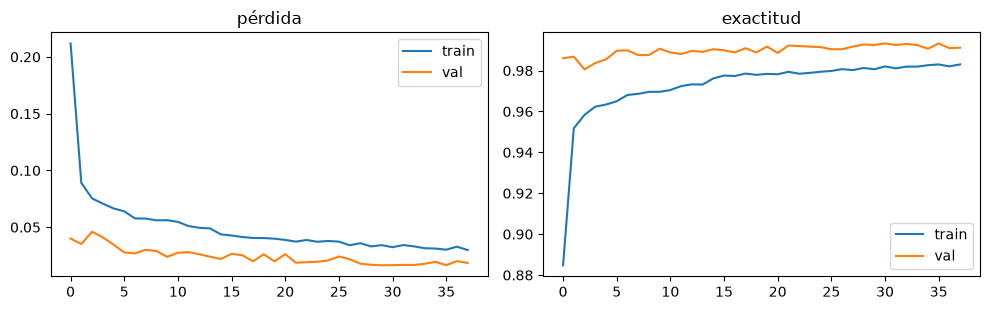

In [9]:
def aumentar(X, y, rng, copias=2):
    Xs, ys = [X], [y]
    for _ in range(copias):
        Xa = X.copy(); ya = y.copy(); m = len(X)
        for k in range(m):
            R = _rot(*rng.normal(0, 4, 3)).astype(np.float32)
            Xa[k, :, :3] = Xa[k, :, :3] @ R.T; Xa[k, :, 3:] = Xa[k, :, 3:] @ R.T
        Xa[:, :, :3] *= rng.uniform(0.95, 1.05, (m, 1, 1)); Xa[:, :, 3:] *= rng.uniform(0.9, 1.1, (m, 1, 1))
        esp = rng.random(m) < 0.5
        Xe = Xa[esp]; Xe[:, :, 1] *= -1; Xe[:, :, 3] *= -1; Xe[:, :, 5] *= -1; Xa[esp] = Xe
        ya[esp] = np.where(ya[esp] == 1, 2, np.where(ya[esp] == 2, 1, 0))
        Xs.append(Xa); ys.append(ya)
    return np.concatenate(Xs), np.concatenate(ys)

Xa, ya = aumentar(Xtr, ytr, np.random.default_rng(SEED))
cnt = np.bincount(ya, minlength=3); pesos = {k: float(len(ya) / (3 * cnt[k])) for k in range(3)}
print("Ventanas de entrenamiento (con aumento):", len(Xa), dict(zip(CLASES, cnt)), "· pesos:", {CLASES[k]: round(v, 2) for k, v in pesos.items()})

modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)]
t0 = time.time()
hist = modelo.fit(Xa, ya, validation_data=(Xva, yva), epochs=60, batch_size=64, class_weight=pesos, callbacks=cb, verbose=2, shuffle=True)
print(f"Entrenado en {time.time() - t0:.0f} s · épocas: {len(hist.history['loss'])} · mejor val_loss: {min(hist.history['val_loss']):.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("pérdida"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="val"); ax[1].set_title("exactitud"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, "evidencias", "curvas_entrenamiento.png"), dpi=110); plt.show()

## 10. Evaluación en personas no vistas (Test)
Exactitud, precisión, recall, F1 por clase y matriz de confusión; **tasa de falsos positivos** (ventanas neutras que encienden una luz); exactitud por persona; **latencia**. Se compara la CNN con la línea base de umbrales.

,exactitud,f1_macro,recall_izq,recall_der,FPR_neutro,lado_equivocado
modelo,,,,,,
1D-CNN,0.9950,0.9872,1.0,1.0,0.0058,0.0
Umbral roll ±14°,0.9696,0.9282,1.0,1.0,0.0352,0.0


Test: 3815 ventanas · {'neutro': 3291, 'izquierda': 259, 'derecha': 265}

CNN — informe por clase:
               precision    recall  f1-score   support

      neutro      1.000     0.994     0.997      3291
   izquierda      0.942     1.000     0.970       259
     derecha      0.989     1.000     0.994       265

    accuracy                          0.995      3815
   macro avg      0.977     0.998     0.987      3815
weighted avg      0.995     0.995     0.995      3815



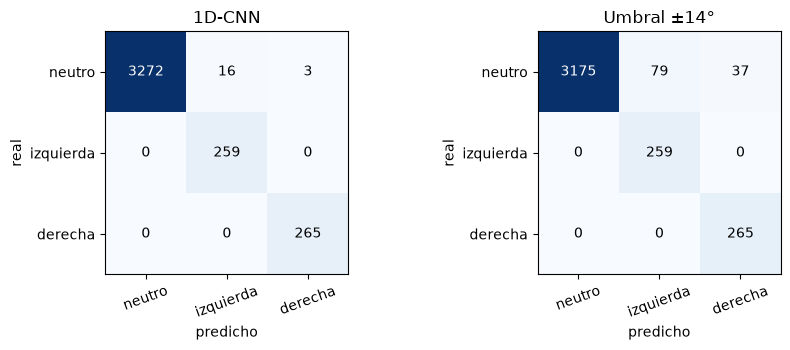

Exactitud por persona de prueba:


,ok_cnn,ok_umbral
persona,,
13,0.998,0.952
14,0.997,0.987
15,0.990,0.969


Latencia Keras en PC: mediana 6.82 ms · p95 9.03 ms (la del microcontrolador se mide en el firmware)


In [10]:
P_cnn = modelo.predict(Xte, verbose=0, batch_size=512); P_thr = predecir_umbral(Xte, T_MEJOR)
def resumen(nombre, P):
    pred = P.argmax(1)
    rep = classification_report(yte, pred, target_names=CLASES, digits=3, output_dict=True, zero_division=0)
    fp = float(((yte == 0) & (pred != 0)).sum() / max((yte == 0).sum(), 1))
    cruz = float((((yte == 1) & (pred == 2)) | ((yte == 2) & (pred == 1))).sum() / max(((yte == 1) | (yte == 2)).sum(), 1))
    return dict(modelo=nombre, exactitud=accuracy_score(yte, pred), f1_macro=rep["macro avg"]["f1-score"],
                recall_izq=rep["izquierda"]["recall"], recall_der=rep["derecha"]["recall"],
                FPR_neutro=fp, lado_equivocado=cruz)
tabla = pd.DataFrame([resumen("1D-CNN", P_cnn), resumen(f"Umbral roll ±{T_MEJOR}°", P_thr)]).set_index("modelo").round(4)
display(tabla)
print(f"Test: {len(yte)} ventanas · {dict(zip(CLASES, np.bincount(yte, minlength=3)))}")
print("\nCNN — informe por clase:\n", classification_report(yte, P_cnn.argmax(1), target_names=CLASES, digits=3, zero_division=0))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, P, tt in zip(ax, (P_cnn, P_thr), ("1D-CNN", f"Umbral ±{T_MEJOR}°")):
    cm = confusion_matrix(yte, P.argmax(1), labels=[0, 1, 2]); a.imshow(cm, cmap="Blues"); a.set_title(tt)
    a.set_xticks(range(3), CLASES, rotation=20); a.set_yticks(range(3), CLASES); a.set_xlabel("predicho"); a.set_ylabel("real")
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "evidencias", "matriz_confusion.png"), dpi=110); plt.show()

por_persona = pd.DataFrame({"persona": mte[:, 0], "ok_cnn": P_cnn.argmax(1) == yte, "ok_umbral": P_thr.argmax(1) == yte}).groupby("persona").mean().round(3)
print("Exactitud por persona de prueba:"); display(por_persona)

# latencia de inferencia en este PC (NO es la del microcontrolador)
x1 = Xte[:1]; _ = modelo(x1, training=False)
lat = []
for _ in range(300):
    t0 = time.perf_counter(); _ = modelo(x1, training=False).numpy(); lat.append((time.perf_counter() - t0) * 1000)
print(f"Latencia Keras en PC: mediana {np.median(lat):.2f} ms · p95 {np.percentile(lat, 95):.2f} ms (la del microcontrolador se mide en el firmware)")

## 11. Evaluación en flujo continuo (lo que realmente hace el casco)
La exactitud por ventana no dice cuántas **señales se detectan**, cuánto **tardan** ni cuántas **luces se encienden sin motivo**. Aquí se reproducen las sesiones de prueba completas con el mismo `Senalizador` que usan el simulador web y el firmware: inferencia cada 10 muestras, umbral de confianza 0,70, encendido tras 2 predicciones iguales, apagado tras 3 sin gesto y límite de 10 s.

In [11]:
class Senalizador:
    """Máquina de estados de las luces. Misma lógica en Python, JavaScript (giro-core.js) y C++ (casco_direccionales.ino)."""
    def __init__(self):
        self.estado = 0; self.pend = 0; self.n_pend = 0; self.n_off = 0; self.t_on = 0.0; self.bloqueado = False; self.n_rearme = 0
    def paso(self, probs, dt):
        k = int(np.argmax(probs)); cand = k if (k != 0 and probs[k] >= UMBRAL_CONF) else 0
        if self.bloqueado:                      # tras 10 s seguidos exige 1 s de neutro para volver a armarse
            self.n_rearme = self.n_rearme + 1 if cand == 0 else 0
            if self.n_rearme >= 5: self.bloqueado = False; self.n_rearme = 0
            return 0
        if cand != 0:
            self.n_off = 0
            if cand != self.estado:
                if cand == self.pend: self.n_pend += 1
                else: self.pend = cand; self.n_pend = 1
                if self.n_pend >= ON_N: self.estado = cand; self.t_on = 0.0; self.pend = 0; self.n_pend = 0
        else:
            self.pend = 0; self.n_pend = 0
            if self.estado != 0:
                self.n_off += 1
                if self.n_off >= OFF_N: self.estado = 0; self.n_off = 0
        if self.estado != 0:
            self.t_on += dt
            if self.t_on >= MAX_SENAL_S: self.estado = 0; self.bloqueado = True; self.n_rearme = 0
        return self.estado

def probs_sesion(X, infer):
    ends = list(range(WIN, len(X) + 1, HOP))
    return np.array(ends), infer(np.stack([X[e - WIN:e] for e in ends]))

def estados_sesion(X, infer, cache=None):
    ends, P = cache if cache is not None else probs_sesion(X, infer)
    sen = Senalizador(); est = [sen.paso(p, HOP / FS) for p in P]
    return ends, np.array(est), P

def evaluar_flujo(ses, infer, cache=None):
    det = tot = mal = 0; retrasos = []; falsas = 0; seg_total = 0.0
    for s in ses:
        c = cache.get((s["persona"], s["sesion"])) if cache else None
        ends, est, _ = estados_sesion(s["X"], infer, c); seg_total += len(s["X"]) / FS
        for cls, ini, fin in s["senales"]:
            tot += 1; ventana = (ends >= ini) & (ends <= fin + FS)
            ok = np.where(ventana & (est == cls))[0]
            if len(ok): det += 1; retrasos.append((ends[ok[0]] - ini) / FS)
            elif (ventana & (est != 0) & (est != cls)).any(): mal += 1
        # tramos encendidos que no se solapan con ninguna señal deliberada
        enc = np.r_[0, (est != 0).astype(int), 0]; ini_t = np.where(np.diff(enc) == 1)[0]
        for a in ini_t:
            m_ini = ends[a]
            if not any(ini - FS <= m_ini <= fin + 2 * FS for _, ini, fin in s["senales"]): falsas += 1
    r = np.array(retrasos) if retrasos else np.array([np.nan])
    return dict(señales=tot, detectadas=det, tasa_deteccion=det / max(tot, 1), lado_equivocado=mal,
                retraso_mediano_s=float(np.median(r)), retraso_p90_s=float(np.nanpercentile(r, 90)),
                falsas_activaciones=falsas, minutos=seg_total / 60, falsas_por_hora=falsas / (seg_total / 3600))

infer_cnn = lambda W: modelo.predict(W, verbose=0, batch_size=512)
infer_thr = lambda W: predecir_umbral(W, T_MEJOR)

### Elegir el umbral de confianza y las confirmaciones con VALIDACIÓN (no con Test)
Se prueban combinaciones y se elige la que **detecta ≥ 98 %** de las señales con **menos falsas activaciones** y, a igualdad, menor retraso. Los valores elegidos se guardan en `metadata.json` y los usan el simulador y el firmware.

In [12]:
ses_val = [s for s in sesiones if s["rol"] == "val"]
cache_val = {(s["persona"], s["sesion"]): probs_sesion(s["X"], infer_cnn) for s in ses_val}
filas = []
for u in (0.6, 0.7, 0.8, 0.9):
    for n_on in (2, 3, 4):
        UMBRAL_CONF, ON_N = u, n_on
        r = evaluar_flujo(ses_val, infer_cnn, cache_val)
        filas.append(dict(umbral=u, confirmaciones=n_on, deteccion=r["tasa_deteccion"], falsas=r["falsas_activaciones"], retraso_mediano_s=r["retraso_mediano_s"]))
barrido = pd.DataFrame(filas)
cand = barrido[barrido.deteccion >= 0.98].sort_values(["falsas", "retraso_mediano_s", "umbral", "confirmaciones"])
elegido = cand.iloc[0] if len(cand) else barrido.sort_values(["deteccion", "falsas"], ascending=[False, True]).iloc[0]
UMBRAL_CONF, ON_N = float(elegido.umbral), int(elegido.confirmaciones)
display(barrido.round(3)); print(f"Elegido con validación → umbral de confianza {UMBRAL_CONF}, {ON_N} confirmaciones (apagado tras {OFF_N}).")

,umbral,confirmaciones,deteccion,falsas,retraso_mediano_s
0,0.6,2,1.000,5,0.50
1,0.6,3,1.000,1,0.70
2,0.6,4,1.000,0,0.90
3,0.7,2,1.000,5,0.54
4,0.7,3,1.000,0,0.74
5,0.7,4,1.000,0,0.94
6,0.8,2,1.000,1,0.60
7,0.8,3,1.000,0,0.80
8,0.8,4,1.000,0,1.00
9,0.9,2,1.000,0,0.60


Elegido con validación → umbral de confianza 0.9, 2 confirmaciones (apagado tras 3).


### Resultado en Test (personas no vistas, sesiones completas)

In [13]:
ses_test = [s for s in sesiones if s["rol"] == "test"]
flujo = pd.DataFrame([dict(modelo="1D-CNN", **evaluar_flujo(ses_test, infer_cnn)),
                      dict(modelo=f"Umbral ±{T_MEJOR}°", **evaluar_flujo(ses_test, infer_thr))]).set_index("modelo").round(3)
display(flujo)
print(f"Atención: {flujo.minutos.iloc[0]:.1f} min de prueba y {int(flujo.señales.iloc[0])} señales: pocas para conclusiones firmes; "
      "las 'falsas por hora' son una extrapolación con intervalo muy ancho.")

,señales,detectadas,tasa_deteccion,lado_equivocado,retraso_mediano_s,retraso_p90_s,falsas_activaciones,minutos,falsas_por_hora
modelo,,,,,,,,,
1D-CNN,61,61,1.0,0,0.56,0.66,1,13.5,4.444
Umbral ±14°,61,61,1.0,0,0.54,0.68,22,13.5,97.778


Atención: 13.5 min de prueba y 61 señales: pocas para conclusiones firmes; las 'falsas por hora' son una extrapolación con intervalo muy ancho.


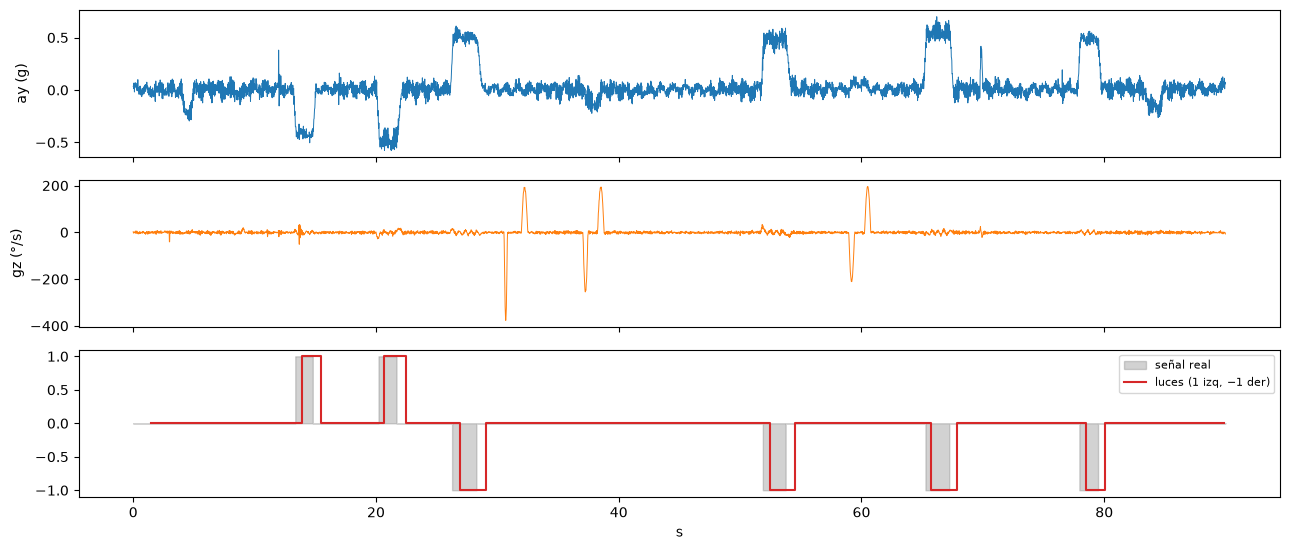

In [14]:
# Línea de tiempo de una sesión de prueba: lo que ve el ciclista (luces) frente a la verdad.
s = ses_test[0]; ends, est, P = estados_sesion(s["X"], infer_cnn); t = ends / FS
fig, ax = plt.subplots(3, 1, figsize=(13, 5.6), sharex=True)
ax[0].plot(np.arange(len(s["X"])) / FS, s["X"][:, 1], lw=.7); ax[0].set_ylabel("ay (g)")
ax[1].plot(np.arange(len(s["X"])) / FS, s["X"][:, 5], lw=.7, color="C1"); ax[1].set_ylabel("gz (°/s)")
ax[2].fill_between(np.arange(len(s["y"])) / FS, 0, (s["y"] != 0) * np.where(s["y"] == 1, 1, -1), step="mid", alpha=.35, color="gray", label="señal real")
ax[2].step(t, np.where(est == 1, 1, np.where(est == 2, -1, 0)), where="post", color="C3", label="luces (1 izq, −1 der)")
ax[2].legend(loc="upper right", fontsize=8); ax[2].set_xlabel("s"); plt.tight_layout()
plt.savefig(os.path.join(OUT, "evidencias", "linea_tiempo_test.png"), dpi=110); plt.show()

## 12. Cinco casos de prueba automatizados (2 en F1, 3 en F2)
Cada caso registra identificador, requisito, precondiciones, datos, pasos, resultado esperado, **resultado obtenido**, estado y evidencia. El estado se **calcula**: un fallo se registra como *Fallido* y no se oculta. Después contraste el comportamiento visible del simulador web (README, sección de pruebas manuales).

In [15]:
class ModeloContado:
    """Envuelve el modelo para comprobar que NO se invoca ante una entrada inválida."""
    def __init__(self, m): self.m = m; self.llamadas = 0
    def __call__(self, W): self.llamadas += 1; return self.m.predict(W, verbose=0)

def clasificar(modelo_c, w):
    ok, msg = validar_ventana(w)
    if not ok: return dict(ok=False, mensaje=msg)
    p = modelo_c(np.asarray(w, np.float32)[None])[0]
    return dict(ok=True, clase=CLASES[int(p.argmax())], puntajes=p.tolist())

mc = ModeloContado(modelo); casos = []
def registrar(id_, req, pre, datos, pasos, esperado, obtenido, estado, evidencia):
    casos.append(dict(ID=id_, Requisito=req, Precondiciones=pre, Datos=datos, Pasos=pasos, Esperado=esperado, Obtenido=obtenido, Estado=estado, Evidencia=evidencia))

# persona de prueba con gesto "estándar" de 20° para casos deterministas
p_cp = crear_persona(np.random.default_rng(7), 99); p_cp.update(tilt_amp=20.0, subida=0.4, meseta=(1.5, 1.5), vib=0.05)

# CP-01 / F1: ventana válida
w_ok = Xte[0]; r = clasificar(mc, w_ok)
registrar("CP-01 / F1", "Aceptar una ventana válida de 6 canales", "Modelo cargado", f"Ventana de test #0, forma {w_ok.shape}",
          "1) validar_ventana  2) clasificar", "Aceptada y clasificada (1 invocación del modelo)",
          f"ok={r['ok']}, clase={r.get('clase')}, llamadas al modelo={mc.llamadas}", "Aprobado" if r["ok"] and mc.llamadas == 1 else "Fallido", "Salida de esta celda")

# CP-02 / F1: NaN o longitud incorrecta -> rechazo sin invocar el modelo
mc.llamadas = 0; w_nan = w_ok.copy(); w_nan[10, 2] = np.nan; w_corta = w_ok[:50]
r1, r2 = clasificar(mc, w_nan), clasificar(mc, w_corta)
registrar("CP-02 / F1", "Rechazar entradas inválidas con mensaje, sin invocar el modelo", "Modelo cargado",
          "Ventana con un NaN y ventana de 50×6", "1) clasificar(NaN)  2) clasificar(50×6)", "Ambas rechazadas con mensaje; 0 invocaciones",
          f"«{r1['mensaje']}» / «{r2['mensaje']}»; llamadas={mc.llamadas}", "Aprobado" if (not r1["ok"] and not r2["ok"] and mc.llamadas == 0) else "Fallido", "Salida de esta celda")

# CP-03 / F2: inclinación izquierda sostenida de 20° -> solo luz izquierda
guion = [(8, "izq", -1)]
X3, y3, sen3 = simular_sesion(np.random.default_rng(31), p_cp, 25, tasa_baches=0, guion=guion)
ends, est, _ = estados_sesion(X3, infer_cnn); valores = set(est.tolist())
registrar("CP-03 / F2", "Inclinación izquierda sostenida de ~20° enciende solo la luz izquierda", "Modelo cargado; ruido bajo",
          "Sesión de 25 s con una inclinación izquierda de 20° y 1,5 s de meseta", "1) reproducir la sesión  2) observar estados",
          "Estado 'izquierda' en algún momento y nunca 'derecha'", f"estados vistos: {sorted(CLASES[i] for i in valores)}",
          "Aprobado" if (1 in valores and 2 not in valores) else "Fallido", "Salida de esta celda")

# CP-04 / F2: bache y vibración con la cabeza recta -> nada
X4, y4, _ = simular_sesion(np.random.default_rng(41), p_cp, 25, tasa_baches=0, guion=[], baches_en=[6, 9, 14, 17])
ends, est, _ = estados_sesion(X4, infer_cnn)
registrar("CP-04 / F2", "Baches y vibración con la cabeza recta no encienden ninguna luz", "Modelo cargado",
          "Sesión de 25 s con cuatro baches de 2 g, sin gestos", "1) reproducir  2) observar estados", "Estado siempre 'neutro'",
          f"muestras de estado ≠ neutro: {int((est != 0).sum())} de {len(est)}", "Aprobado" if (est != 0).sum() == 0 else "Fallido", "Salida de esta celda")

# CP-05 / F2: determinismo
a = modelo.predict(w_ok[None], verbose=0)[0]; b = modelo.predict(w_ok[None], verbose=0)[0]
dif = float(np.abs(a - b).max()); mismo = a.argmax() == b.argmax(); rango = bool(((a >= 0) & (a <= 1)).all() and ((b >= 0) & (b <= 1)).all())
registrar("CP-05 / F2", "Misma ventana → misma clase y |Δpuntaje| ≤ 0,000001; puntajes en [0,1]", "Mismo modelo",
          "Ventana de test #0 clasificada dos veces", "1) predecir  2) predecir  3) comparar", "Clase igual, Δ ≤ 1e-6, puntajes en [0,1]",
          f"clase igual={mismo}, Δ={dif:.2e}, rango ok={rango}", "Aprobado" if (mismo and dif <= 1e-6 and rango) else "Fallido", "Salida de esta celda")

tabla_cp = pd.DataFrame(casos); tabla_cp.to_csv(os.path.join(OUT, "evidencias", "casos_de_prueba.csv"), index=False)
display(tabla_cp[["ID", "Esperado", "Obtenido", "Estado"]])
print("Resumen:", tabla_cp.Estado.value_counts().to_dict())

,ID,Esperado,Obtenido,Estado
0,CP-01 / F1,Aceptada y clasificada (1 invocación del modelo),"ok=True, clase=neutro, llamadas al modelo=1",Aprobado
1,CP-02 / F1,Ambas rechazadas con mensaje; 0 invocaciones,«La ventana contiene valores NaN o infinitos.»...,Aprobado
2,CP-03 / F2,Estado 'izquierda' en algún momento y nunca 'd...,"estados vistos: ['izquierda', 'neutro']",Aprobado
3,CP-04 / F2,Estado siempre 'neutro',muestras de estado ≠ neutro: 0 de 118,Aprobado
4,CP-05 / F2,"Clase igual, Δ ≤ 1e-6, puntajes en [0,1]","clase igual=True, Δ=0.00e+00, rango ok=True",Aprobado


Resumen: {'Aprobado': 5}


## 13. Revisión, checklist y control de cambios
**Checklist** (marque con evidencia, no de memoria):
- [ ] Requisitos F1/F2 y criterios de aceptación escritos antes de entrenar.
- [ ] Datos: origen, personas, fechas y condiciones registradas; sin NaN; frecuencia verificada.
- [ ] **Separación por persona** comprobada (la celda 7 lanza un error si una persona aparece en train y test).
- [ ] Test no se usó para elegir T, épocas ni arquitectura.
- [ ] Falsos positivos y detección medidos **en flujo**, no solo por ventana.
- [ ] Casos CP-01..CP-05 ejecutados; los fallos están registrados.
- [ ] Modelo, configuración, manifiesto y versiones guardados; hay un ZIP anterior para revertir.
- [ ] Limitaciones y advertencias de seguridad visibles en la documentación.

**Hallazgos para registrar** (dos como mínimo; complete con *sus* resultados): descríbalo, su impacto y una mejora. Ejemplos de dónde mirar: comparación CNN vs. umbral en la sección 11; falsas activaciones por hora; retraso de detección; sesgo de datos sintéticos.

**Desarrollo, pruebas y producción:** publicar el simulador educativo no equivale a un pase a producción. Para ello se exigen revisión, pruebas aprobadas con **grabaciones reales de personas distintas**, pruebas en carretera cerrada y un procedimiento de reversión (por ejemplo, volver al modo de umbrales o a la luz fija).

## 14. Exportar el modelo
Se conserva el `.keras`, se genera un **SavedModel** con entrada float32 `[lote, 75, 6]` (unidades físicas: g y °/s; la normalización ya está dentro) y a partir de él:
1. **TFLite int8** (microcontrolador con TensorFlow Lite Micro) y `model_data.h`. Su entrada es la señal ya normalizada (el firmware la normaliza antes de cuantizar).
2. **Pesos en C++** (`pesos_cnn.h`) para el motor de inferencia propio `motor_cnn.h`, sin dependencias.
3. **TF.js GraphModel** (`model.json` + `.bin` + `metadata.json`) para el simulador web.

La salida son tres puntuaciones en el orden `neutro, izquierda, derecha`. **No divida ni normalice la entrada fuera del modelo.**

In [16]:
M = os.path.join(OUT, "modelo"); SM = os.path.join(M, "saved_model"); WEB = os.path.join(M, "web_model"); FW = os.path.join(OUT, "firmware")
for d in (WEB, FW): os.makedirs(d, exist_ok=True)
if os.path.isdir(SM): shutil.rmtree(SM)
if os.path.isdir(WEB): shutil.rmtree(WEB); os.makedirs(WEB)
modelo.save(os.path.join(M, "casco_cnn1d.keras"))
modelo.export(SM)                                   # SavedModel con firma serving_default
print("Guardados: casco_cnn1d.keras y SavedModel")

# --- TFLite float32 e int8 completo ---
# Un tensor de entrada int8 tiene UNA sola escala. Mezclar g (±2) y °/s (±500) la arruinaría (la aceleración quedaría aplastada
# a cero). Por eso el modelo TFLite recibe la señal YA normalizada (z-scores) y el firmware normaliza antes de cuantizar.
sub = tf.keras.Model(modelo.get_layer("normalizacion").output, modelo.output, name="casco_sin_norm")
SM_T = os.path.join(M, "saved_model_tflite")
if os.path.isdir(SM_T): shutil.rmtree(SM_T)
sub.export(SM_T)
norm_f = lambda W: ((W - mu) / sd).astype(np.float32)
Xtr_n = norm_f(Xtr); rep_idx = np.random.default_rng(SEED).choice(len(Xtr), 400, replace=False)
def dataset_rep():
    for i in rep_idx: yield [Xtr_n[i:i + 1]]
conv = tf.lite.TFLiteConverter.from_saved_model(SM_T); tflite_f32 = conv.convert()
conv = tf.lite.TFLiteConverter.from_saved_model(SM_T)
conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.representative_dataset = dataset_rep
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
tflite_i8 = conv.convert()
open(os.path.join(M, "casco_f32.tflite"), "wb").write(tflite_f32); open(os.path.join(M, "casco_int8.tflite"), "wb").write(tflite_i8)
print(f"TFLite float32: {len(tflite_f32) / 1024:.1f} KB · int8: {len(tflite_i8) / 1024:.1f} KB")

itp = tf.lite.Interpreter(model_content=tflite_i8); itp.allocate_tensors()
d_in, d_out = itp.get_input_details()[0], itp.get_output_details()[0]
s_in, z_in = d_in["quantization"]; s_out, z_out = d_out["quantization"]
print("Entrada int8: escala", s_in, "· punto cero", z_in, "| Salida int8: escala", s_out, "· punto cero", z_out)
operaciones = sorted({o["op_name"] for o in itp._get_ops_details()} - {"DELEGATE"})
print("Operaciones TFLite necesarias (para el resolvedor de TFLite Micro):", operaciones)

def infer_tflite(W):
    out = np.empty((len(W), 3), np.float32); Wn = norm_f(W)
    for k, w in enumerate(Wn):
        q = np.clip(np.round(w / s_in + z_in), -128, 127).astype(np.int8)[None]
        itp.set_tensor(d_in["index"], q); itp.invoke()
        out[k] = (itp.get_tensor(d_out["index"])[0].astype(np.float32) - z_out) * s_out
    return out
P_i8 = infer_tflite(Xte)
acuerdo = float((P_i8.argmax(1) == P_cnn.argmax(1)).mean())
print(f"TFLite int8 en Test: exactitud {accuracy_score(yte, P_i8.argmax(1)):.4f} (float: {accuracy_score(yte, P_cnn.argmax(1)):.4f}) · coincidencia de clase con Keras: {acuerdo:.4f}")

def a_cabecera(nombre, datos, ruta):
    lineas = [f"// Generado por el cuaderno. {len(datos)} bytes.", "#pragma once", f"alignas(8) const unsigned char {nombre}[] = {{"]
    for i in range(0, len(datos), 12): lineas.append("  " + ", ".join(f"0x{b:02x}" for b in datos[i:i + 12]) + ",")
    lineas += ["};", f"const unsigned int {nombre}_len = {len(datos)};"]; open(ruta, "w").write("\n".join(lineas) + "\n")
a_cabecera("model_data", tflite_i8, os.path.join(FW, "model_data.h"))
open(os.path.join(FW, "cuantizacion.h"), "w").write(
    f"#pragma once\n// Cuantización del modelo int8. La entrada es la señal NORMALIZADA: z = (x - NORM_MEAN) / NORM_STD (ver pesos_cnn.h) y luego q = round(z / Q_IN_SCALE) + Q_IN_ZERO.\nconst float Q_IN_SCALE = {s_in:.9g}f;\nconst int Q_IN_ZERO = {int(z_in)};\n"
    f"const float Q_OUT_SCALE = {s_out:.9g}f;\nconst int Q_OUT_ZERO = {int(z_out)};\n")

INFO:tensorflow:Assets written to: salida/modelo/saved_model/assets


INFO:tensorflow:Assets written to: salida/modelo/saved_model/assets


Saved artifact at 'salida/modelo/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 75, 6), dtype=tf.float32, name='ventana')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140141428310288: TensorSpec(shape=(1, 1, 6), dtype=tf.float32, name=None)
  140141428310096: TensorSpec(shape=(1, 1, 6), dtype=tf.float32, name=None)
  140141459110992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428311824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141459109840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428310864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428312016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428312592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428313360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428314896: TensorSpec(shape=(), dtype=tf.resource, name=None)


Guardados: casco_cnn1d.keras y SavedModel


INFO:tensorflow:Assets written to: salida/modelo/saved_model_tflite/assets


INFO:tensorflow:Assets written to: salida/modelo/saved_model_tflite/assets


Saved artifact at 'salida/modelo/saved_model_tflite'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 75, 6), dtype=tf.float32, name='keras_tensorCLONE')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140141459110992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428311824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141459109840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428310864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428312016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428312592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428313360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140141428314896: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1793466576.788862    1797 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793466576.788907    1797 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1793466576.794761    1797 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


W0000 00:00:1793466577.282455    1797 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793466577.282505    1797 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


TFLite float32: 30.6 KB · int8: 15.2 KB
Entrada int8: escala 0.13692165911197662 · punto cero 8 | Salida int8: escala 0.00390625 · punto cero -128
Operaciones TFLite necesarias (para el resolvedor de TFLite Micro): ['CONV_2D', 'EXPAND_DIMS', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'MEAN', 'RESHAPE', 'SOFTMAX']
TFLite int8 en Test: exactitud 0.9958 (float: 0.9950) · coincidencia de clase con Keras: 0.9992


310

In [17]:
# --- Pesos en C++ ---
def arr(nombre, a):
    a = np.asarray(a, np.float32).ravel()
    return f"static const float {nombre}[{len(a)}] = {{\n  " + ",\n  ".join(", ".join(f"{v:.9g}f" for v in a[i:i + 8]) for i in range(0, len(a), 8)) + "\n};\n"
c1, c2, c3, de = (modelo.get_layer(n) for n in ("conv1", "conv2", "conv3", "clase"))
norm = modelo.get_layer("normalizacion")
mean_n = np.asarray(norm.mean).ravel(); var_n = np.asarray(norm.variance).ravel()
K1, C1_ = c1.kernel.shape[0], c1.kernel.shape[2]; K2, C2_ = c2.kernel.shape[0], c2.kernel.shape[2]; K3, C3_ = c3.kernel.shape[0], c3.kernel.shape[2]
h = ["// Generado por el cuaderno: pesos de la 1D-CNN (formato Keras: núcleo [k][entrada][salida]).", "#pragma once",
     f"#define CASCO_WIN {WIN}", f"#define CASCO_N_CH {N_CH}", f"#define CASCO_K1 {K1}", f"#define CASCO_C1 {C1_}",
     f"#define CASCO_K2 {K2}", f"#define CASCO_C2 {C2_}", f"#define CASCO_K3 {K3}", f"#define CASCO_C3 {C3_}",
     "#define CASCO_L1 (CASCO_WIN / 2)", "#define CASCO_L2 (CASCO_L1 / 2)", "#define CASCO_N_CLASES 3",
     arr("NORM_MEAN", mean_n), arr("NORM_STD", np.sqrt(var_n)),
     arr("W1", c1.kernel.numpy()), arr("B1", c1.bias.numpy()), arr("W2", c2.kernel.numpy()), arr("B2", c2.bias.numpy()),
     arr("W3", c3.kernel.numpy()), arr("B3", c3.bias.numpy()), arr("WD", de.kernel.numpy()), arr("BD", de.bias.numpy())]
open(os.path.join(FW, "pesos_cnn.h"), "w").write("\n".join(h))

MOTOR_H = r'''// motor_cnn.h — inferencia float de la 1D-CNN del casco, sin bibliotecas externas.
// Copia exacta de las capas Keras: Normalization -> Conv1D(same)+ReLU -> MaxPool(2) -> Conv1D+ReLU -> MaxPool(2)
// -> Conv1D+ReLU -> GlobalAveragePooling -> Dense -> Softmax.
#pragma once
#include <math.h>
#include "pesos_cnn.h"

class MotorCNN {
 public:
  // x: CASCO_WIN * CASCO_N_CH valores (fila = muestra; columnas ax, ay, az, gx, gy, gz) en g y grados/s.
  // probs: 3 valores (neutro, izquierda, derecha).
  void inferir(const float* x, float* probs) {
    for (int t = 0; t < CASCO_WIN; t++)
      for (int c = 0; c < CASCO_N_CH; c++)
        xn_[t * CASCO_N_CH + c] = (x[t * CASCO_N_CH + c] - NORM_MEAN[c]) / NORM_STD[c];
    conv1d(xn_, CASCO_WIN, CASCO_N_CH, W1, B1, CASCO_K1, CASCO_C1, a1_);
    pool2(a1_, CASCO_WIN, CASCO_C1, p1_);
    conv1d(p1_, CASCO_L1, CASCO_C1, W2, B2, CASCO_K2, CASCO_C2, a2_);
    pool2(a2_, CASCO_L1, CASCO_C2, p2_);
    conv1d(p2_, CASCO_L2, CASCO_C2, W3, B3, CASCO_K3, CASCO_C3, a3_);
    float g[CASCO_C3];
    for (int c = 0; c < CASCO_C3; c++) {
      float s = 0; for (int t = 0; t < CASCO_L2; t++) s += a3_[t * CASCO_C3 + c];
      g[c] = s / CASCO_L2;
    }
    float logit[CASCO_N_CLASES], m = -1e30f;
    for (int o = 0; o < CASCO_N_CLASES; o++) {
      float s = BD[o]; for (int c = 0; c < CASCO_C3; c++) s += g[c] * WD[c * CASCO_N_CLASES + o];
      logit[o] = s; if (s > m) m = s;
    }
    float z = 0; for (int o = 0; o < CASCO_N_CLASES; o++) { probs[o] = expf(logit[o] - m); z += probs[o]; }
    for (int o = 0; o < CASCO_N_CLASES; o++) probs[o] /= z;
  }

 private:
  float xn_[CASCO_WIN * CASCO_N_CH];
  float a1_[CASCO_WIN * CASCO_C1], p1_[CASCO_L1 * CASCO_C1];
  float a2_[CASCO_L1 * CASCO_C2], p2_[CASCO_L2 * CASCO_C2];
  float a3_[CASCO_L2 * CASCO_C3];

  static void conv1d(const float* in, int L, int cin, const float* W, const float* B, int K, int cout, float* out) {
    const int pad = (K - 1) / 2;                       // 'same' con núcleo impar
    for (int t = 0; t < L; t++)
      for (int co = 0; co < cout; co++) {
        float s = B[co];
        for (int k = 0; k < K; k++) {
          int ti = t + k - pad; if (ti < 0 || ti >= L) continue;
          const float* xi = in + ti * cin; const float* w = W + (k * cin) * cout + co;
          for (int ci = 0; ci < cin; ci++) s += xi[ci] * w[ci * cout];
        }
        out[t * cout + co] = s > 0 ? s : 0;            // ReLU
      }
  }
  static void pool2(const float* in, int L, int c, float* out) {
    for (int t = 0; t < L / 2; t++)
      for (int k = 0; k < c; k++) {
        float a = in[(2 * t) * c + k], b = in[(2 * t + 1) * c + k]; out[t * c + k] = a > b ? a : b;
      }
  }
};
'''
open(os.path.join(FW, "motor_cnn.h"), "w").write(MOTOR_H)
print("Escritos pesos_cnn.h y motor_cnn.h en", FW)

Escritos pesos_cnn.h y motor_cnn.h en salida/firmware


### Verificación: el motor C++ debe dar lo mismo que Keras
Si hay `g++`, se compila el motor y se compara con Keras en 300 ventanas de prueba. Esta es la comprobación que garantiza que lo que se ejecutará en el casco es el mismo modelo.

In [18]:
paridad = None
if shutil.which("g++"):
    prueba = r'''#include <cstdio>
#include <vector>
#include "motor_cnn.h"
int main(int argc, char** argv) {
  FILE* f = fopen(argv[1], "rb"); int n = atoi(argv[2]); std::vector<float> w(CASCO_WIN * CASCO_N_CH);
  static MotorCNN m; float p[3];
  for (int i = 0; i < n; i++) { if (fread(w.data(), 4, w.size(), f) != w.size()) return 1; m.inferir(w.data(), p); printf("%.9g %.9g %.9g\n", p[0], p[1], p[2]); }
  return 0; }
'''
    open(os.path.join(FW, "prueba_paridad.cpp"), "w").write(prueba)
    N = 300; Xte[:N].astype("<f4").tofile(os.path.join(FW, "ventanas.bin"))
    r = subprocess.run(["g++", "-O2", "-o", "paridad", "prueba_paridad.cpp"], cwd=FW, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    sal = subprocess.run(["./paridad", "ventanas.bin", str(N)], cwd=FW, capture_output=True, text=True).stdout.split()
    P_cpp = np.array(sal, np.float32).reshape(-1, 3)
    paridad = dict(ventanas=N, dif_max=float(np.abs(P_cpp - P_cnn[:N]).max()), clase_igual=float((P_cpp.argmax(1) == P_cnn[:N].argmax(1)).mean()))
    print("Paridad C++ vs Keras:", paridad)
    for f in ("paridad", "ventanas.bin", "prueba_paridad.cpp"): os.remove(os.path.join(FW, f))
else:
    print("g++ no disponible: se omite la verificación (en Colab sí está).")

Paridad C++ vs Keras: {'ventanas': 300, 'dif_max': 1.1920928955078125e-07, 'clase_igual': 1.0}


In [19]:
# --- TensorFlow.js ---
web_ok = False
if tfjs is not None:
    try:
        tfjs.converters.convert_tf_saved_model(SM, WEB)    # GraphModel
        bins = [f for f in os.listdir(WEB) if f.endswith(".bin")]
        web_ok = os.path.exists(os.path.join(WEB, "model.json")) and len(bins) >= 1
        print("Archivos web:", sorted(os.listdir(WEB)), "→", "OK" if web_ok else "FALTAN ARCHIVOS")
    except Exception as e:
        print("La conversión a TF.js falló:", repr(e)[:300], "\nRevise versiones (README: Problemas conocidos). El resto de la práctica sigue siendo válida.")
else:
    print("tensorflowjs no está disponible:", TFJS_VERSION)

acc_test = float(accuracy_score(yte, P_cnn.argmax(1)))
metadata = {"labels": CLASES, "inputShape": [WIN, N_CH], "channels": CANALES, "sampleRateHz": FS, "hop": HOP,
            "inputType": "float32", "units": {"accel": "g", "gyro": "deg/s"}, "normalization": "included_in_model",
            "axes": "x adelante, y izquierda, z arriba; roll>0 = inclinar a la derecha (ay>0)",
            "confidenceThreshold": UMBRAL_CONF, "onConsecutive": ON_N, "offConsecutive": OFF_N, "maxSignalSeconds": MAX_SENAL_S,
            "modelType": "GraphModel", "tensorflowjs": TFJS_VERSION, "tensorflow": tf.__version__, "base": "1D-CNN desde cero",
            "parameters": int(modelo.count_params()), "testAccuracy": round(acc_test, 4),
            "trainedOn": "datos reales" if USAR_DATOS_REALES else "datos SINTÉTICOS (solo valida el flujo)",
            "limitation": "Tres clases. No detecta gestos desconocidos; puntajes no calibrados; no certificado."}
json.dump(metadata, open(os.path.join(WEB, "metadata.json"), "w"), indent=2, ensure_ascii=False)
if web_ok:
    zp = os.path.join(M, "modelo_web.zip")
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(os.listdir(WEB)): z.write(os.path.join(WEB, f), f)
    print("Creado", zp, f"({os.path.getsize(zp) / 1024:.0f} KB). Descomprímalo y reemplace dist/model completo.")

Archivos web: ['group1-shard1of1.bin', 'model.json'] → OK
Creado salida/modelo/modelo_web.zip (25 KB). Descomprímalo y reemplace dist/model completo.


I0000 00:00:1793466578.409032    1797 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1793466578.409193    1797 single_machine.cc:361] Starting new session


## 15. Evidencias y cierre
Se guardan métricas, configuración, versiones y huellas. Compruebe que puede volver a ejecutar el cuaderno (las semillas fijas reproducen los datos sintéticos; con datos reales conserve los CSV).

In [20]:
resultados = dict(versiones=VERSIONES, semilla=SEED, datos="reales" if USAR_DATOS_REALES else "sintéticos",
    ventanas=dict(train=len(ytr), val=len(yva), test=len(yte)), umbral_T=T_MEJOR,
    ventana_metricas=tabla.reset_index().to_dict("records"), flujo=flujo.reset_index().to_dict("records"),
    tflite_int8=dict(kb=round(len(tflite_i8) / 1024, 1), exactitud=float(accuracy_score(yte, P_i8.argmax(1))), coincidencia_con_keras=acuerdo, operaciones=operaciones),
    paridad_cpp=paridad, casos_de_prueba=tabla_cp.Estado.value_counts().to_dict(), parametros=int(modelo.count_params()),
    latencia_keras_pc_ms=dict(mediana=float(np.median(lat)), p95=float(np.percentile(lat, 95))))
json.dump(resultados, open(os.path.join(OUT, "evidencias", "resultados.json"), "w"), indent=2, ensure_ascii=False, default=float)
json.dump(metadata, open(os.path.join(OUT, "evidencias", "config_modelo.json"), "w"), indent=2, ensure_ascii=False)
zp = os.path.join(OUT, "paquete_casco.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for base in (M, FW, os.path.join(OUT, "evidencias")):
        for raiz, _, fs in os.walk(base):
            if "saved_model" in raiz: continue
            for f in fs: z.write(os.path.join(raiz, f), os.path.relpath(os.path.join(raiz, f), OUT))
print("Paquete listo:", zp, f"({os.path.getsize(zp) / 1024:.0f} KB)")
try:                                    # descarga automática en Colab
    from google.colab import files; files.download(zp)
except Exception: pass

Paquete listo: salida/paquete_casco.zip (549 KB)


## 16. Qué sigue: datos reales (imprescindible antes de usarlo en la calle)
1. Cargue `firmware/captura_datos/captura_datos.ino` en la placa y ejecute `python herramientas/captura_serial.py --persona 1 --sesion 0`. Durante la grabación pulse `n` (neutro), `l` (izquierda) o `r` (derecha) para etiquetar.
2. Grabe **al menos 8–10 personas**, 3 sesiones de 5–10 min cada una, con casco puesto, en bicicleta (calle tranquila o rodillo) e incluyendo baches, frenadas y mirar sobre el hombro. Anote persona, fecha, casco y condiciones.
3. Copie los CSV a `datos_reales/p01_s0.csv`, … y fije `USAR_DATOS_REALES = True` en la sección 5. Ejecute todo de nuevo: división por persona, entrenamiento, evaluación en flujo y exportación se repiten sin más cambios.
4. Compare el **rendimiento en flujo** del modelo CNN y del umbral con **personas que no entrenaron**. Si el umbral basta, despliegue el umbral: es más simple, más fácil de explicar y de revertir.